<a href="https://colab.research.google.com/github/intanoktavianipresia/Studi_Kasus_Deep_Learning/blob/main/Sesi_6_Satellite_Imagery_Analisis_Vegetasi.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 31.1 MB/s eta 0:00:00
Masukkan Google Cloud Project ID: civil-charmer-512201-p0
Google Earth Engine berhasil diinisialisasi.


Map(center=[-3.1, 101.8], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

Citra 2023-01-01 sampai 2023-12-31: 89 citra
Citra 2024-01-01 sampai 2024-12-31: 61 citra
NDVI berhasil dihitung untuk kedua periode.


Map(center=[-3.1, 101.8], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

,Periode,Rata-rata NDVI
0,Awal,0.470838
1,Akhir,0.490430


NDVI rata-rata periode awal : 0.4708
NDVI rata-rata periode akhir: 0.4904
Perubahan NDVI              : 0.0196


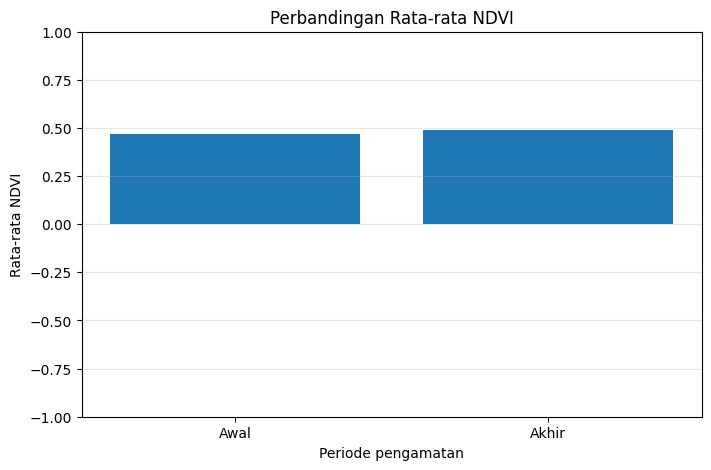


INTERPRETASI HASIL
Perubahan rata-rata NDVI relatif kecil berdasarkan ambang analisis sederhana ini.

Catatan: penurunan NDVI tidak otomatis membuktikan terjadinya deforestasi. Perubahan dapat dipengaruhi musim, awan, panen, kebakaran, atau faktor lainnya.

KESIMPULAN:
1. Data citra Sentinel-2 digunakan untuk memantau vegetasi.
2. NDVI dihitung dari kanal inframerah dekat dan merah.
3. Dua periode dibandingkan untuk melihat perubahan vegetasi.
4. Peta dan grafik membantu menyajikan hasil secara visual.
5. Indikasi deforestasi memerlukan verifikasi tambahan,
   misalnya pemeriksaan tutupan lahan dan citra resolusi tinggi.



In [1]:
# ============================================================
# SESI 6: SATELLITE IMAGERY & AI
# Studi Kasus: Analisis Perubahan Tutupan Vegetasi
# Sumber data: Sentinel-2 dan ESA WorldCover
# ============================================================

# 1. INSTALASI DAN AUTENTIKASI GOOGLE EARTH ENGINE

!pip -q install earthengine-api geemap

import ee
import geemap
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ee.Authenticate()
ee.Initialize(project=input("Masukkan Google Cloud Project ID: ").strip())

print("Google Earth Engine berhasil diinisialisasi.")


# ============================================================
# 2. MENENTUKAN WILAYAH PENELITIAN
# Contoh: wilayah Bengkulu Utara
# ============================================================

wilayah = ee.Geometry.Rectangle([
    101.40, -3.80,
    102.30, -2.45
])

peta = geemap.Map(center=[-3.1, 101.8], zoom=9)
peta.add_basemap("SATELLITE")
peta.addLayer(
    wilayah,
    {"color": "yellow"},
    "Wilayah penelitian"
)

display(peta)


# ============================================================
# 3. MENGAMBIL DATA CITRA SATELIT SENTINEL-2
# ============================================================

def ambil_citra(tanggal_mulai, tanggal_selesai):
    koleksi = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(wilayah)
        .filterDate(tanggal_mulai, tanggal_selesai)
        .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", 30))
        .select(["B4", "B8", "SCL"])
    )

    jumlah = koleksi.size().getInfo()
    print(
        f"Citra {tanggal_mulai} sampai {tanggal_selesai}: "
        f"{jumlah} citra"
    )

    if jumlah == 0:
        raise ValueError(
            "Tidak ada citra pada periode ini. "
            "Coba ubah rentang tanggal."
        )

    return koleksi.median().clip(wilayah)


# Bandingkan dua periode yang berbeda.
# Periode dapat diganti sesuai kebutuhan penelitian.

citra_awal = ambil_citra("2023-01-01", "2023-12-31")
citra_akhir = ambil_citra("2024-01-01", "2024-12-31")


# ============================================================
# 4. MENGHITUNG NDVI
# NDVI = (NIR - RED) / (NIR + RED)
# Sentinel-2: B8 = NIR, B4 = RED
# ============================================================

def hitung_ndvi(citra):
    return citra.normalizedDifference(
        ["B8", "B4"]
    ).rename("NDVI")


ndvi_awal = hitung_ndvi(citra_awal)
ndvi_akhir = hitung_ndvi(citra_akhir)

print("NDVI berhasil dihitung untuk kedua periode.")


# ============================================================
# 5. VISUALISASI NDVI DAN PERUBAHANNYA
# ============================================================

parameter_ndvi = {
    "min": -0.2,
    "max": 0.8,
    "palette": ["brown", "yellow", "lightgreen", "darkgreen"]
}

peta_ndvi = geemap.Map(center=[-3.1, 101.8], zoom=9)
peta_ndvi.addLayer(
    ndvi_awal,
    parameter_ndvi,
    "NDVI periode awal"
)
peta_ndvi.addLayer(
    ndvi_akhir,
    parameter_ndvi,
    "NDVI periode akhir"
)

perubahan_ndvi = ndvi_akhir.subtract(ndvi_awal).rename(
    "Perubahan_NDVI"
)

peta_ndvi.addLayer(
    perubahan_ndvi,
    {
        "min": -0.5,
        "max": 0.5,
        "palette": ["red", "white", "green"]
    },
    "Perubahan NDVI"
)

peta_ndvi.addLayer(
    wilayah,
    {"color": "blue"},
    "Batas wilayah"
)

display(peta_ndvi)


# ============================================================
# 6. MENGHITUNG STATISTIK NDVI
# ============================================================

statistik_awal = ndvi_awal.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=wilayah,
    scale=100,
    maxPixels=1e9,
    bestEffort=True
).getInfo()

statistik_akhir = ndvi_akhir.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=wilayah,
    scale=100,
    maxPixels=1e9,
    bestEffort=True
).getInfo()

nilai_awal = statistik_awal.get("NDVI")
nilai_akhir = statistik_akhir.get("NDVI")

if nilai_awal is None or nilai_akhir is None:
    raise ValueError(
        "Statistik NDVI tidak tersedia. "
        "Periksa wilayah, tanggal, dan ketersediaan citra."
    )

selisih = nilai_akhir - nilai_awal

hasil = pd.DataFrame({
    "Periode": ["Awal", "Akhir"],
    "Rata-rata NDVI": [nilai_awal, nilai_akhir]
})

display(hasil)

print(f"NDVI rata-rata periode awal : {nilai_awal:.4f}")
print(f"NDVI rata-rata periode akhir: {nilai_akhir:.4f}")
print(f"Perubahan NDVI              : {selisih:.4f}")


# ============================================================
# 7. GRAFIK PERBANDINGAN NDVI
# ============================================================

plt.figure(figsize=(8, 5))

plt.bar(
    hasil["Periode"],
    hasil["Rata-rata NDVI"]
)

plt.title("Perbandingan Rata-rata NDVI")
plt.xlabel("Periode pengamatan")
plt.ylabel("Rata-rata NDVI")
plt.ylim(-1, 1)
plt.grid(axis="y", alpha=0.3)
plt.show()


# ============================================================
# 8. INTERPRETASI HASIL
# ============================================================

print("\nINTERPRETASI HASIL")

if selisih < -0.05:
    print(
        "Rata-rata NDVI menurun. "
        "Hal ini mengindikasikan penurunan kehijauan vegetasi."
    )
elif selisih > 0.05:
    print(
        "Rata-rata NDVI meningkat. "
        "Hal ini mengindikasikan peningkatan kehijauan vegetasi."
    )
else:
    print(
        "Perubahan rata-rata NDVI relatif kecil "
        "berdasarkan ambang analisis sederhana ini."
    )

print(
    "\nCatatan: penurunan NDVI tidak otomatis membuktikan "
    "terjadinya deforestasi. Perubahan dapat dipengaruhi "
    "musim, awan, panen, kebakaran, atau faktor lainnya."
)


# ============================================================
# 9. KESIMPULAN
# ============================================================

print("""
KESIMPULAN:
1. Data citra Sentinel-2 digunakan untuk memantau vegetasi.
2. NDVI dihitung dari kanal inframerah dekat dan merah.
3. Dua periode dibandingkan untuk melihat perubahan vegetasi.
4. Peta dan grafik membantu menyajikan hasil secara visual.
5. Indikasi deforestasi memerlukan verifikasi tambahan,
   misalnya pemeriksaan tutupan lahan dan citra resolusi tinggi.
""")